# 05 — Evaluation: Family A vs. Family B
Combines the cross-validated results from `03_imbalance_classification.ipynb`
and `04_anomaly_detection.ipynb` with the two reference baselines, tests
whether the differences are statistically significant, and answers the
study's core research questions (RQ3, RQ5).

Significance is judged with the **corrected resampled t-test**
(Nadeau & Bengio, 2003) and intervals with the matching corrected
t-based CI, because repeated-CV fold scores are not independent.
The Wilcoxon / raw-fold Friedman results are still saved as an
(optimistic) sensitivity check.

**Scope:** like 03 and 04, this uses one 125-row training split
(`random_state=42`). `07_robustness.ipynb` shows this split is unusually
favourable to Family A; the full-dataset comparison there is the more
reliable basis for conclusions (see Summary).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

from src.evaluation import (
    friedman_test, pairwise_wilcoxon, pairwise_corrected_ttest,
    cv_split_sizes, N_SPLITS
)
from src.reporting import TABLES_DIR, save_figure, save_table, save_json

# CV in 03/04 runs on the 80% training split, so the corrected tests
# need that split's per-fold train/test sizes.
TEST_SIZE = 0.2
RANDOM_STATE = 42
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")
train_df, _ = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE,
                               stratify=df["employment_status"])
N_TRAIN, N_TEST = cv_split_sizes(len(train_df), N_SPLITS)
print(f"CV on {len(train_df)} rows: n_train={N_TRAIN:.0f}, n_test={N_TEST:.0f} per fold")

CV on 125 rows: n_train=100, n_test=25 per fold


## Load results from both families

In [2]:
family_a_summary = pd.read_csv(TABLES_DIR / "family_a_cv_summary.csv", index_col=0)
family_b_summary = pd.read_csv(TABLES_DIR / "family_b_cv_summary.csv", index_col=0)
baseline_summary = pd.read_csv(TABLES_DIR / "baseline_cv_summary.csv", index_col=0)

with open(TABLES_DIR / "family_a_raw_scores.pkl", "rb") as f:
    family_a_scores = pickle.load(f)
with open(TABLES_DIR / "family_b_raw_scores.pkl", "rb") as f:
    family_b_scores = pickle.load(f)
with open(TABLES_DIR / "baseline_raw_scores.pkl", "rb") as f:
    baseline_scores = pickle.load(f)

# Family A vs. B tests use the seven study models only; baselines are
# compared separately below.
all_scores = {**family_a_scores, **family_b_scores}
combined_summary = pd.concat([
    family_a_summary.assign(family="A"),
    family_b_summary.assign(family="B"),
    baseline_summary.assign(family="Baseline"),
]).sort_values("pr_auc", ascending=False)

## RQ3 — Which approach achieves the highest PR-AUC?

,accuracy,precision,recall,f1,pr_auc,roc_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,roc_auc_std,pr_auc_ci_low,pr_auc_ci_high,pr_auc_corrected_ci_low,pr_auc_corrected_ci_high,base_rate
A1_RandomForest_ClassWeighted,0.715,0.329,0.372,0.333,0.416,0.650,0.085,0.181,0.212,0.166,0.131,0.108,0.381,0.453,0.278,0.554,0.2
A4_ADASYN_RandomForest,0.738,0.332,0.292,0.295,0.408,0.672,0.069,0.220,0.171,0.162,0.109,0.102,0.379,0.438,0.294,0.523,0.2
A3_SMOTE_RandomForest,0.732,0.308,0.260,0.272,0.399,0.650,0.073,0.203,0.151,0.153,0.116,0.113,0.368,0.432,0.277,0.521,0.2
A2_XGBoost_ScalePosWeight,0.690,0.298,0.352,0.302,0.386,0.613,0.084,0.192,0.190,0.144,0.136,0.133,0.350,0.426,0.243,0.529,0.2
BL2_LogReg_Balanced,0.594,0.261,0.496,0.334,0.343,0.620,0.119,0.135,0.220,0.148,0.119,0.119,0.312,0.377,0.218,0.469,0.2
B1_IsolationForest,0.536,0.251,0.664,0.362,0.282,0.531,0.097,0.079,0.228,0.113,0.097,0.156,0.256,0.309,0.180,0.384,0.2
B3_LocalOutlierFactor,0.752,0.047,0.024,0.031,0.241,0.456,0.039,0.132,0.065,0.085,0.085,0.162,0.219,0.266,0.151,0.331,0.2
B2_OneClassSVM,0.535,0.109,0.184,0.134,0.207,0.370,0.094,0.096,0.159,0.113,0.058,0.133,0.191,0.224,0.146,0.268,0.2
BL1_Dummy_Prior,0.800,0.000,0.000,0.000,0.200,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.200,0.200,0.200,0.200,0.2


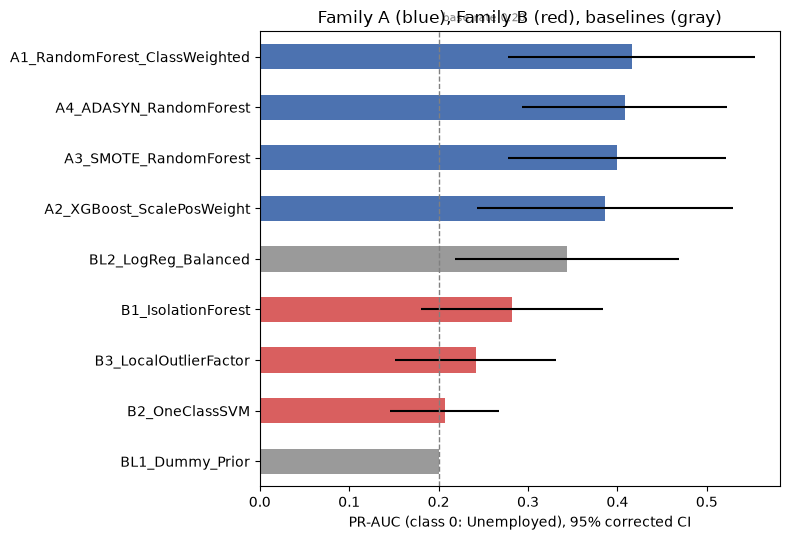

,family,pr_auc,roc_auc,base_rate
A1_RandomForest_ClassWeighted,A,0.416,0.650,0.2
A4_ADASYN_RandomForest,A,0.408,0.672,0.2
A3_SMOTE_RandomForest,A,0.399,0.650,0.2
A2_XGBoost_ScalePosWeight,A,0.386,0.613,0.2
BL2_LogReg_Balanced,Baseline,0.343,0.620,0.2
B1_IsolationForest,B,0.282,0.531,0.2
B3_LocalOutlierFactor,B,0.241,0.456,0.2
B2_OneClassSVM,B,0.207,0.370,0.2
BL1_Dummy_Prior,Baseline,0.200,0.500,0.2


In [3]:
display(combined_summary.drop(columns="family").round(3))
save_table(combined_summary, "combined_cv_summary")

fig, ax = plt.subplots(figsize=(8, 5.5))
palette = {"A": "#4c72b0", "B": "#d95f5f", "Baseline": "#9a9a9a"}
colors = [palette[f] for f in combined_summary["family"]]
xerr = [
    combined_summary["pr_auc"] - combined_summary["pr_auc_corrected_ci_low"],
    combined_summary["pr_auc_corrected_ci_high"] - combined_summary["pr_auc"],
]
combined_summary["pr_auc"].plot(kind="barh", ax=ax, color=colors, xerr=xerr)
base_rate = combined_summary["base_rate"].iloc[0]
ax.axvline(base_rate, linestyle="--", color="gray", linewidth=1)
ax.text(base_rate, -0.7, f" base rate {base_rate:.2f}", color="gray", fontsize=8)
ax.set_xlabel("PR-AUC (class 0: Unemployed), 95% corrected CI")
ax.set_title("Family A (blue), Family B (red), baselines (gray)")
ax.invert_yaxis()
plt.tight_layout()
save_figure(fig, "combined_pr_auc_comparison")
plt.show()

display(combined_summary[["family", "pr_auc", "roc_auc", "base_rate"]].round(3))

## RQ5 — Are unemployed graduates better characterized as a minority class or as anomalous observations?

Answered by the Friedman test (is there a significant difference
among ALL models' cross-validated PR-AUC?) followed by pairwise
corrected resampled t-tests (which specific pairs differ?),
Bonferroni-corrected across 21 pairs at α=0.05.

In [4]:
# Primary: blocks are the 10 CV repeats (fold scores averaged within
# each repeat), since the 50 raw folds aren't independent blocks.
friedman_result = friedman_test(all_scores, n_splits=N_SPLITS)
friedman_raw = friedman_test(all_scores)
print("Friedman test (all models, per-repeat blocks):", friedman_result)
print("Friedman test (raw folds, optimistic):       ", friedman_raw)
save_json({"per_repeat": friedman_result, "raw_folds": friedman_raw}, "friedman_result");

Friedman test (all models, per-repeat blocks): {'statistic': np.float64(50.74285714285713), 'p_value': np.float64(3.335722546191291e-09), 'significant_at_0.05': np.True_}
Friedman test (raw folds, optimistic):        {'statistic': np.float64(145.25142857142873), 'p_value': np.float64(7.801214113788888e-29), 'significant_at_0.05': np.True_}


In [5]:
# Primary: Nadeau-Bengio corrected resampled t-test.
corrected_results = pairwise_corrected_ttest(
    all_scores, N_TRAIN, N_TEST, alpha=0.05, correction="bonferroni"
)
display(corrected_results.round(4))
save_table(corrected_results, "pairwise_corrected_ttest", index=False)

# Sensitivity check only — treats folds as independent, so optimistic.
wilcoxon_results = pairwise_wilcoxon(all_scores, alpha=0.05, correction="bonferroni")
save_table(wilcoxon_results, "pairwise_wilcoxon", index=False);

,model_a,model_b,mean_diff,statistic,p_value,significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,0.2011,2.8502,0.0064,False
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,0.2089,2.6419,0.0110,False
13,A3_SMOTE_RandomForest,B2_OneClassSVM,0.1919,2.5619,0.0135,False
9,A2_XGBoost_ScalePosWeight,B2_OneClassSVM,0.1790,2.1049,0.0405,False
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,0.1668,2.0387,0.0469,False
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,0.1746,1.9810,0.0532,False
18,B1_IsolationForest,B2_OneClassSVM,0.0750,1.9360,0.0586,False
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,0.1577,1.8461,0.0709,False
15,A4_ADASYN_RandomForest,B1_IsolationForest,0.1261,1.5703,0.1228,False
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,0.1339,1.5602,0.1251,False


**Reading this table:** each row's `p_value` comes from the corrected
resampled t-test (Nadeau & Bengio, 2003), which inflates the variance
of the fold-score differences by `(1/k + n_test/n_train)` instead of
`1/k`. Repeated-CV folds share most of their training rows, so a test
that treats the 50 fold scores as independent (the Wilcoxon test
saved to `pairwise_wilcoxon.csv`) understates the variance and
overstates significance. Each p-value is compared against a
Bonferroni-corrected α (0.05 / 21 pairs = 0.00238).

In [6]:
FAMILY_A = set(family_a_summary.index)
FAMILY_B = set(family_b_summary.index)

def which_family(model_name):
    return "A" if model_name in FAMILY_A else "B"

wilcoxon_sig = {
    (r.model_a, r.model_b): r.significant for r in wilcoxon_results.itertuples()
}

corrected_results["family_a"] = corrected_results["model_a"].apply(which_family)
corrected_results["family_b"] = corrected_results["model_b"].apply(which_family)
corrected_results["wilcoxon_significant"] = [
    wilcoxon_sig[(a, b)] for a, b in zip(corrected_results["model_a"], corrected_results["model_b"])
]

cols = ["model_a", "model_b", "mean_diff", "p_value", "significant", "wilcoxon_significant"]
cross_family = corrected_results[corrected_results["family_a"] != corrected_results["family_b"]]
print("Cross-family comparisons (classification vs. anomaly detection):")
display(cross_family[cols].round(4))
save_table(cross_family[cols], "cross_family_tests", index=False);

Cross-family comparisons (classification vs. anomaly detection):


,model_a,model_b,mean_diff,p_value,significant,wilcoxon_significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,0.2011,0.0064,False,True
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,0.2089,0.0110,False,True
13,A3_SMOTE_RandomForest,B2_OneClassSVM,0.1919,0.0135,False,True
9,A2_XGBoost_ScalePosWeight,B2_OneClassSVM,0.1790,0.0405,False,True
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,0.1668,0.0469,False,True
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,0.1746,0.0532,False,True
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,0.1577,0.0709,False,True
15,A4_ADASYN_RandomForest,B1_IsolationForest,0.1261,0.1228,False,True
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,0.1339,0.1251,False,True
10,A2_XGBoost_ScalePosWeight,B3_LocalOutlierFactor,0.1447,0.1361,False,True


## Comparison against the reference baselines

Each study model vs. the prior-only dummy (BL1) and the class-weighted
logistic regression (BL2), corrected resampled t-test, Bonferroni across
these 14 comparisons. Beating BL1 shows a model ranks better than
chance; beating BL2 is what would justify a more complex model.

In [7]:
from src.evaluation import corrected_resampled_ttest

rows = []
for model, scores in all_scores.items():
    for bl, bl_scores in baseline_scores.items():
        t_stat, p = corrected_resampled_ttest(scores, bl_scores, N_TRAIN, N_TEST)
        rows.append({"model": model, "baseline": bl,
                     "mean_diff": scores.mean() - bl_scores.mean(),
                     "statistic": t_stat, "p_value": p})
vs_baseline = pd.DataFrame(rows)
alpha_vs_baseline = 0.05 / len(vs_baseline)
vs_baseline["significant"] = vs_baseline["p_value"] < alpha_vs_baseline
print(f"Bonferroni alpha = {alpha_vs_baseline:.4f}")
display(vs_baseline.round(4))
save_table(vs_baseline, "vs_baseline_tests", index=False);

Bonferroni alpha = 0.0036


,model,baseline,mean_diff,statistic,p_value,significant
0,A1_RandomForest_ClassWeighted,BL1_Dummy_Prior,0.2159,3.1398,0.0029,True
1,A1_RandomForest_ClassWeighted,BL2_LogReg_Balanced,0.0725,1.0401,0.3034,False
2,A2_XGBoost_ScalePosWeight,BL1_Dummy_Prior,0.1860,2.6069,0.0121,False
3,A2_XGBoost_ScalePosWeight,BL2_LogReg_Balanced,0.0427,0.5323,0.5969,False
4,A3_SMOTE_RandomForest,BL1_Dummy_Prior,0.1990,3.2799,0.0019,True
5,A3_SMOTE_RandomForest,BL2_LogReg_Balanced,0.0556,0.8347,0.4079,False
6,A4_ADASYN_RandomForest,BL1_Dummy_Prior,0.2082,3.6531,0.0006,True
7,A4_ADASYN_RandomForest,BL2_LogReg_Balanced,0.0648,1.0292,0.3084,False
8,B1_IsolationForest,BL1_Dummy_Prior,0.0820,1.6188,0.1119,False
9,B1_IsolationForest,BL2_LogReg_Balanced,-0.0613,-0.8288,0.4113,False


## Nested cross-validation

Nested cross-validation for all models (hyperparameters tuned inside each
outer fold, on all 157 rows) is in `08_nested_cv.ipynb`. It replaces the
earlier one-off A1 run, which wasn't captured in a notebook.


## Summary

On this training split (seed 42):

- **Highest CV PR-AUC:** A1 — class-weighted Random Forest (0.416, 95%
  corrected CI [0.278, 0.554]), ahead of logistic regression (0.343) and
  Family B (0.207–0.282). All CIs overlap widely.
- **Significance:** no pair of the seven study models differs
  significantly (smallest p = 0.006, A4 vs. B2, against Bonferroni
  α = 0.00238). No study model is significantly better than logistic
  regression. A1, A3 and A4
  significantly beat the dummy baseline; A2 and the Family B models don't
  after correction.
- **ROC-AUC:** Family A 0.61–0.67, logistic regression 0.62, Family B
  0.37–0.53 (B2 and B3 below chance).
- **Holdout:** A1 scores PR-AUC 0.149 on the 32-row holdout (6
  unemployed), below the 0.19 base rate.

**This split is not representative.** `07_robustness.ipynb` repeats the
same protocol with four other split seeds, and logistic regression has the
highest PR-AUC on all four. On the full dataset (`07`) and under nested
cross-validation (`08`), logistic regression is highest, Family A is ahead
of Family B in most pairs, and no difference is significant. The study's
conclusions are stated in the README's "Headline result" and are based on
notebooks 06–08, not on this notebook alone.
